In [74]:
import gdsfactory as gf
import numpy as np
import components as comp
import importlib

In [75]:
importlib.reload(comp)
gf.clear_cache()

In [76]:
c = gf.Component('TOP')

## Fiber bonding

In [77]:
wb = c << comp.wirebondingFiberBondingTemplate()

## adding y branches

In [78]:
## grating couplers connectors
#y1 = c << comp.yEbeam()
y2 = c << comp.yEbeam()
#y3 = c << comp.yEbeam()
y4 = c << comp.yEbeam()
#y1.rotate(90)
y2.rotate(-90)
#y3.rotate(90)
y4.rotate(-90)

#y1.x = (wb['o12'].x + wb['o13'].x)/2
#y1.y = wb['o9'].y - 100
#y3.x = (wb['o12'].x + wb['o13'].x)/2
#y3.y = wb['o9'].y - 100

y2.x = wb['o12'].x 
y2.y = 4211

y4.x = wb['o13'].x
y4.y = 4211

## Adding Bragg gratings

In [79]:
Nbg1 = 45
N2bg1 = 104
pds = np.array([320,322, 318,316])
bg1 = c << comp.bragg(Nbg1, pds[0])
bg2 = c << comp.bragg(N2bg1, pds[0])
bg3 = c << comp.bragg(N2bg1, pds[0])
bg4 = c << comp.bragg(Nbg1, pds[0])

bg5 = c << comp.bragg(45, pds[1])
bg6 = c << comp.bragg(104, pds[1])
bg7 = c << comp.bragg(104, pds[1])
bg8 = c << comp.bragg(45, pds[1])

bg9 = c << comp.bragg(45, pds[2]) #2
bg10 = c << comp.bragg(104, pds[2])
bg11 = c << comp.bragg(104, pds[2])
bg12 = c << comp.bragg(45, pds[2])

bg13 = c << comp.bragg(45, pds[3])
bg14 = c << comp.bragg(104, pds[3])
bg15 = c << comp.bragg(104, pds[3])
bg16 = c << comp.bragg(45, pds[3])


## Rotating gratings

In [80]:
bgs = [bg1, bg2, bg3, bg4, bg5, bg6, bg7, bg8, 
       bg9, bg10, bg11, bg12, bg13, bg14, bg15, bg16]

for bg in bgs:
    bg.rotate(-90)

## Positioning Bragg gratings

In [81]:
## positioning
pds = pds/1e3
bg1.x = (wb['o11'].x + wb['o12'].x)/2 + 80
bg1.y = y2['o2'].y - 100

bg2.rotate(180)
bg2.x = bg1.x
bg2.y = bg1.y - (Nbg1 + N2bg1) * pds[0] / 2 - pds[0]

bg3.x = bg2.x
bg3.y = bg2.y - (N2bg1 + N2bg1) * pds[0] / 2 - pds[0]

bg4.rotate(180)
bg4.x = bg3.x
bg4.y = bg3.y - (Nbg1 + N2bg1) * pds[0] / 2 - pds[0]
## second set
bg5.x = (wb['o12'].x + wb['o13'].x)/2 - 80
bg5.y = y2['o2'].y - 100

bg6.rotate(180)
bg6.x = bg5.x
bg6.y = bg5.y - (Nbg1 + N2bg1) * pds[1] / 2 - pds[1]

bg7.x = bg6.x
bg7.y = bg6.y - (N2bg1 + N2bg1) * pds[1] / 2 - pds[1]

bg8.rotate(180)
bg8.x = bg7.x
bg8.y = bg7.y - (Nbg1 + N2bg1) * pds[1] / 2 - pds[1]

## third set
bg9.x = (wb['o12'].x + wb['o13'].x)/2 + 80
bg9.y = y4['o2'].y - 100

bg10.rotate(180)
bg10.x = bg9.x
bg10.y = bg9.y - (Nbg1 + N2bg1) * pds[2] / 2 - pds[2]

bg11.x = bg10.x
bg11.y = bg10.y - (N2bg1 + N2bg1) * pds[2] / 2 - pds[2]

bg12.rotate(180)
bg12.x = bg11.x
bg12.y = bg11.y - (Nbg1 + N2bg1) * pds[2] / 2 - pds[2]

## fourth set
bg13.x = (wb['o13'].x + wb['o14'].x)/2 - 80
bg13.y = y4['o2'].y - 100

bg14.rotate(180)
bg14.x = bg13.x
bg14.y = bg13.y - (Nbg1 + N2bg1) * pds[3] / 2 - pds[3]

bg15.x = bg14.x
bg15.y = bg14.y - (N2bg1 + N2bg1) * pds[3] / 2 - pds[3]

bg16.rotate(180)
bg16.x = bg15.x
bg16.y = bg15.y - (Nbg1 + N2bg1) * pds[3] / 2 - pds[3]


## Adding phase shifers 1000 $\mu$m

In [82]:
ps1 = c << comp.phaseShifter1000u()
ps1.x = 720 + 1637.1/2
ps1.y = 1850
ps2 = c << comp.phaseShifter1000u()
ps2.mirror(p1=(0,0), p2=(0,1)) #flip horizontal
ps2.y = ps1.y 
ps2.x = -(500 + 1637.1/2)
ps3 = c << comp.phaseShifter1000u()
ps3.x = ps1.x
ps3.y = 650
ps4 = c << comp.phaseShifter1000u2x2()
ps4.mirror(p1=(0,0), p2=(0,1)) #flip horizontal
ps4.x = ps2.x 
ps4.y = 650

## Adding a fifth phase shifter to be tested separately

In [83]:
ps5 = c << comp.phaseShifter1000u2x2()

ps5.x = ps1.x + 1483

ps5.y = ps1.y + 1200

## Photonics connections

#### Connecting Bragg gratings to y branches

In [84]:
## grating couplers
route1 = gf.routing.route_single(
    c,
    wb['o12'],
    y2.ports['o1'],
    radius=5,
    cross_section='strip',
    start_straight_length=10,
)
'''
route2 = gf.routing.route_single(
    c,
    wb['o13'],
    y1.ports['o2'],
    radius=5,
    start_straight_length=10,
    cross_section='strip',
)'''

route3 = gf.routing.route_single(
    c,
    wb['o13'],
    y4.ports['o1'],
    radius=5,
    cross_section='strip',
    start_straight_length=10,
)
'''
route4 = gf.routing.route_single(
    c,
    wb['o15'],
    y3.ports['o2'],
    radius=5,
    start_straight_length=10,
    cross_section='strip',
)'''
'''## input splitters connection
route5 = gf.routing.route_single(
    c,
    y2.ports['o1'],
    y1.ports['o1'],
    radius=5,
    cross_section='strip',
    start_straight_length=10,
)

route6 = gf.routing.route_single(
    c,
    y4.ports['o1'],
    y3.ports['o1'],
    radius=5,
    start_straight_length=10,
    cross_section='strip',
)'''

"## input splitters connection\nroute5 = gf.routing.route_single(\n    c,\n    y2.ports['o1'],\n    y1.ports['o1'],\n    radius=5,\n    cross_section='strip',\n    start_straight_length=10,\n)\n\nroute6 = gf.routing.route_single(\n    c,\n    y4.ports['o1'],\n    y3.ports['o1'],\n    radius=5,\n    start_straight_length=10,\n    cross_section='strip',\n)"

#### Bragg gratings connections

In [85]:
## first set
routey_bg1 = gf.routing.route_single(
    c,
    y2.ports['o2'],
    bg1.ports['o1'],
    radius=5,
    start_straight_length=5,
    cross_section='strip',
)
route_bg1_2 = gf.routing.route_single(
    c,
    bg1.ports['o2'],
    bg2.ports['o2'],
    cross_section='strip',
)
route_bg2_3 = gf.routing.route_single(
    c,
    bg2.ports['o1'],
    bg3.ports['o1'],
    cross_section='strip',
)
route_bg3_4 = gf.routing.route_single(
    c,
    bg3.ports['o2'],
    bg4.ports['o2'],
    cross_section='strip',
)

## second set
route_y_bg2 = gf.routing.route_single(
    c,
    y2.ports['o3'],
    bg5.ports['o1'],
    radius=5,
    start_straight_length=5,
    cross_section='strip',
)
route_bg5_6 = gf.routing.route_single(
    c,
    bg5.ports['o2'],
    bg6.ports['o2'],
    cross_section='strip',
)
route_bg6_7 = gf.routing.route_single(
    c,
    bg6.ports['o1'],
    bg7.ports['o1'],
    cross_section='strip',
)
route_bg7_8 = gf.routing.route_single(
    c,
    bg7.ports['o2'],
    bg8.ports['o2'],
    cross_section='strip',
)
## third set
route_y_bg9 = gf.routing.route_single(
    c,
    y4.ports['o2'],
    bg9.ports['o1'],
    radius=5,
    start_straight_length=5,
    cross_section='strip',
)
route_bg9_10 = gf.routing.route_single(
    c,
    bg9.ports['o2'],
    bg10.ports['o2'],
    cross_section='strip',
)
route_bg10_11 = gf.routing.route_single(
    c,
    bg10.ports['o1'],
    bg11.ports['o1'],
    cross_section='strip',
)
route_bg11_12 = gf.routing.route_single(
    c,
    bg11.ports['o2'],
    bg12.ports['o2'],
    cross_section='strip',
)
## fourth set
route_ybg13 = gf.routing.route_single(
    c,
    y4.ports['o3'],
    bg13.ports['o1'],
    radius=5,
    start_straight_length=5,
    cross_section='strip',
)
route_bg13_14 = gf.routing.route_single(
    c,
    bg13.ports['o2'],
    bg14.ports['o2'],
    cross_section='strip',
)
route_bg14_15 = gf.routing.route_single(
    c,
    bg14.ports['o1'],
    bg15.ports['o1'],
    cross_section='strip',
)
route_bg15_16 = gf.routing.route_single(
    c,
    bg15.ports['o2'],
    bg16.ports['o2'],
    cross_section='strip',
)

#### From Bragg gratings to phase shifters 1 and 2

In [86]:
route_bgs_ps2 = gf.routing.route_bundle(
    c,
    [bg4.ports['o1'],bg8.ports['o1']],
    [ps2.ports['o1'], ps2.ports['o2']],
    start_straight_length=200,
    cross_section='strip',
    path_length_matching_config={"element": 1, "loop_side":gf.routing.LoopSide.right, "loops": 1, "loop_position": gf.routing.LoopPosition.center}
)

route_bgs_ps1 = gf.routing.route_bundle(
    c,
    [bg12.ports['o1'],bg16.ports['o1']],
    [ps1.ports['o2'], ps1.ports['o1']],
    start_straight_length=200,
    cross_section='strip',
    path_length_matching_config={"element": 1, "loop_side":gf.routing.LoopSide.left, "loops": 1, "loop_position": gf.routing.LoopPosition.center}
)

#### from ps1 and ps2 to ps3

In [87]:
'''
route_ps1_2_ps3 = gf.routing.route_bundle(
    c,
    [ps1.ports['o3'], ps2.ports['o3']],
    [ps3.ports['o1'], ps3.ports['o2']],
    start_straight_length=200,
    cross_section='strip',
    #path_length_matching_config={"element": 0, "loop_side":gf.routing.LoopSide.left, "loops": 3, "loop_position": gf.routing.LoopPosition.start}
)
'''
route_ps1_ps2 = gf.routing.route_single(
    c,
    ps1.ports['o3'],
    ps3.ports['o1'],
    start_straight_length=300,
    cross_section='strip',
    steps = [
        {'dx': -300, 'dy': 0},
        {'dx': 0, 'dy': -300},
        {'dx': 150 + 372.1, 'dy': 0}, #due to path length matching
        {'dx': 0, 'dy': -150},
        {'dx': -150 - 372.1, 'dy': 0}, #due to path length matching
        {'dx': 0, 'y': ps3.ports['o1'].y},
    ]
)
route_ps2_ps3 = gf.routing.route_single(
    c,
    ps2.ports['o3'],
    ps3.ports['o2'],
    start_straight_length=300,
    cross_section='strip',
    steps = [
        {'dx': 800, 'dy': 0},
        {'dx': 0, 'dy': -300},
        {'dx': -150, 'dy': 0},
        {'dx': 0, 'dy': -150},
        {'dx': 150, 'dy': 0},
        {'dx': 0, 'y': ps3.ports['o2'].y},
    ]
)


In [88]:
(route_ps2_ps3.length - route_ps1_ps2.length)/1e3, ((route_ps2_ps3.length - route_ps1_ps2.length)/1e3)/2

(-4.656612873077393e-13, -2.3283064365386963e-13)

#### from ps3 to ps4 (unbalanced MZI with $\Delta L = 120.4 \mu m$)

In [89]:
y5 = c << comp.yEbeam()
y5.rotate(180)
y5.y = (ps4['o1'].y + ps4['o2'].y)/2
y5.x = ps3['o1'].x - 630

In [90]:
delta = 120.4
route_ps4_y5_upper = gf.routing.route_single(
    c,
    y5.ports['o2'],
    ps4.ports['o1'],
    
    cross_section='strip',
    steps =[
        {'dx': -20, 'dy': 0},
        {'dx': 0, 'y': ps4.ports['o1'].y},
    ]
)
route_ps4_y5_lower = gf.routing.route_single(
    c,
    y5.ports['o3'],
    ps4.ports['o2'],
    
    cross_section='strip',
    steps =[
        {'dx': -20, 'dy': 0},
        {'dx': 0, 'y': ps4.ports['o2'].y},
    ]
)

route_ps3_y5 = gf.routing.route_single(
    c,
    ps3.ports['o3'],
    y5.ports['o1'],
    start_straight_length=10,
    cross_section='strip',
    steps = [
        {'dx': -510, 'dy': 0},
        {'dx': 0, 'y': y5.ports['o1'].y}
    ]
)

#### ps4 to output gcs

In [91]:
route_ps4_out1 = gf.routing.route_single(
    c,
    ps4.ports['o3'],
    wb['o10'],
    start_straight_length=10,
    cross_section='strip',
    steps = [
                {'dx': 20, 'dy': 0},
                {'dx': 0, 'dy': -50},
                {'dx': -1850, 'dy': 0},
                {'dx': 0, 'y': wb['o10'].y - 1600},

                {'dx': 500, 'dy': 0},
                {'dx': 0, 'dy': 50},
                {'dx': 20, 'dy': 0},
                {'dx': 0, 'dy': -50},

                {'x': wb['o10'].x, 'dy': 0},
                
            ]
    
)
half_delta = 215.5

route_ps4_out2 = gf.routing.route_single(
    c,
    ps4.ports['o4'],
    wb['o11'],
    start_straight_length=10,
    cross_section='strip',
    steps = [
            {'dx': 20, 'dy': 0},
            {'dx': 0, 'dy': 50},
            {'dx': -1750, 'dy': 0},
            {'dx': 0, 'y': wb['o11'].y - 1700},
            
            {'dx': 1670, 'dy': 0},
            {'dx': 0, 'dy': 50 + half_delta},
            {'dx': 20, 'dy': 0},
            {'dx': 0, 'dy': -50 - half_delta},

            {'x': wb['o11'].x, 'dy': 0},
            
        ]
)


In [92]:
((route_ps4_out1.length - route_ps4_out2.length)/1e3)/2 

4.656612873077393e-13

### Ps5 Mzi connections

In [93]:
## adding y branch to make a MZI

ymzi_test = c << comp.yEbeam()

ymzi_test.x = ps5.ports['o1'].x - 550

ymzi_test.y = ( ps5.ports['o1'].y + ps5.ports['o2'].y)/2

In [94]:
route_y_gc = gf.routing.route_single(
    c,
    wb['o17'],
    ymzi_test.ports['o1'],
    start_straight_length=10,
    cross_section='strip',
)

## unbalanced MZI
# delta = 120.4
route_ps5_y_upper = gf.routing.route_single(
    c,
    ymzi_test.ports['o3'],
    ps5.ports['o1'],
    cross_section='strip',
    steps =[
        {'dx': 20, 'dy': 0},
        {'dx': 0, 'y': ps5.ports['o1'].y},
    ]
    
    
)
route_ps5_y_lower = gf.routing.route_single(
    c,
    ymzi_test.ports['o2'],
    ps5.ports['o2'],
    cross_section='strip',
    steps =[
        {'dx': 20, 'dy': 0},
        {'dx': 0, 'y': ps5.ports['o2'].y},
    
        
    ]
)

half_delta2 = 534.5

route_ps5_gc = gf.routing.route_single(
    c,
    ps5.ports['o3'],
    wb['o15'],
    cross_section='strip',
    steps =[
        {'dx': -40, 'dy': 0},
        {'dx': 0, 'dy': -60},
        
        {'dx': 1700, 'dy': 0},  
        {'dx': 0, 'dy': -260},

        {'dx': -3050, 'dy': 0},
        {'dx': 0, 'dy': 50 + half_delta2},
        {'dx': -20, 'dy': 0},
        {'dx': 0, 'dy': -50 - half_delta2},

        {'x': wb['o15'].x, 'dy': 0}, 
    ]
)

route_ps5_gc_2 = gf.routing.route_single(
    c,
    ps5.ports['o4'],
    wb['o14'],
    cross_section='strip',
    steps =[
        {'dx': -40, 'dy': 0},
        {'dx': 0, 'dy': 60},
        {'dx': 1750, 'dy': 0},
        {'dx': 0, 'dy': -870},
        {'dx': -2500, 'dy': 0},
        {'dx': 0, 'dy': 50 },
        {'dx': -20, 'dy': 0},
        {'dx': 0, 'dy': -50 },
        {'x': wb['o14'].x, 'dy': 0},   
    ]
)

In [95]:
((route_ps5_gc_2.length - route_ps5_gc.length)/1e3)/2

-4.656612873077393e-13

## metal wiring

In [96]:
taper_length = 100
width = 86
tapers = []
for i in range(12):
    taper = c << gf.components.taper(
        length=taper_length,
        width1=width,
        width2=wb[f'e{i+1}'].width,   
        layer=(12, 0),
        port_names=('e_in', 'e_out'),
        port_types=('electrical', 'electrical'),
    )
    taper.connect('e_out', wb[f'e{i+1}'])
    tapers.append(taper)

for i in range(3):
    tapers[i].connect('e_out', wb[f'e{39-i}'])

    gf.routing.route_single_electrical(
        c, ps1.ports[f'e{i+1}'], tapers[i].ports['e_in'],
        cross_section='metal_routing',
        layer=(12, 0),
        width=width,
        
    )
    
for i in range(3):
    tapers[i+3].connect('e_out', wb[f'e{36-i}'])

    gf.routing.route_single_electrical(
        c, ps3.ports[f'e{i+1}'], tapers[i+3].ports['e_in'],
        cross_section='metal_routing',
        layer=(12, 0),
        width=width,
        
    )
    
for i in range(3):
    tapers[i+6].connect('e_out', wb[f'e{17-i}'])

    gf.routing.route_single_electrical(
        c, ps2.ports[f'e{i+1}'], tapers[i+6].ports['e_in'],
        cross_section='metal_routing',
        layer=(12, 0),
        width=width,
        
    )

for i in range(3):  
    tapers[i+9].connect('e_out', wb[f'e{14-i}'])

    gf.routing.route_single_electrical(
        c, ps4.ports[f'e{i+1}'], tapers[i+9].ports['e_in'],
        cross_section='metal_routing',
        layer=(12, 0),
        width=width,

    )


### additional phase shifter connections

tapers2 = []

for i in range(3):
    taper = c << gf.components.taper(
        length=taper_length,
        width1=width,
        width2=wb[f'e{i+1}'].width,   
        layer=(12, 0),
        port_names=('e_in', 'e_out'),
        port_types=('electrical', 'electrical'),
    )
    taper.connect('e_out', wb[f'e{i+40}']) #20 to 18
    tapers2.append(taper)


for i in range(3):  
    tapers2[i].connect('e_out', wb[f'e{42-i}'])

    gf.routing.route_single_electrical(
        c, ps5.ports[f'e{i+1}'], tapers2[i].ports['e_in'],
        cross_section='metal_routing',
        layer=(12, 0),
        width=width,

    )

### Strain circuit

In [97]:
## grating couplers connectors
#y1 = c << comp.yEbeam()
y2_s = c << comp.yEbeam()
#y3 = c << comp.yEbeam()
y4_s = c << comp.yEbeam()
#y1.rotate(90)
y2_s.rotate(90)
#y3.rotate(90)
y4_s.rotate(90)

#y1.x = (wb['o12'].x + wb['o13'].x)/2
#y1.y = wb['o9'].y - 100
#y3.x = (wb['o12'].x + wb['o13'].x)/2
#y3.y = wb['o9'].y - 100

y2_s.x = wb['o4'].x 
y2_s.y = wb['o4'].y + 113

y4_s.x = wb['o5'].x
y4_s.y = wb['o5'].y + 113

In [98]:
N = np.array([135,312,390,312,135])

pd = 320
bg1_s = c << comp.bragg(N[0], pd)
bg2_s = c << comp.bragg(N[1], pd)
bg3_s = c << comp.bragg(N[2], pd)
bg4_s = c << comp.bragg(N[3], pd)
bg5_s = c << comp.bragg(N[4], pd)
#bg6_s = c << comp.bragg(N[5], pd)
#bg7_s = c << comp.bragg(N[6], pd)

bg8_s = c << comp.bragg(N[0], pd)
bg9_s = c << comp.bragg(N[1], pd)
bg10_s = c << comp.bragg(N[2], pd)
bg11_s = c << comp.bragg(N[3], pd)
bg12_s = c << comp.bragg(N[4], pd)
#bg13_s = c << comp.bragg(N[5], pd)
#bg14_s = c << comp.bragg(N[6], pd)
'''
bg15_s = c << comp.bragg(N[0], pd)
bg16_s = c << comp.bragg(N[1], pd)
bg17_s = c << comp.bragg(N[2], pd)
bg18_s = c << comp.bragg(N[3], pd)
bg19_s = c << comp.bragg(N[4], pd)
bg20_s = c << comp.bragg(N[5], pd)
bg21_s = c << comp.bragg(N[6], pd)

bg22_s = c << comp.bragg(N[0], pd)
bg23_s = c << comp.bragg(N[1], pd)
bg24_s = c << comp.bragg(N[2], pd)
bg25_s = c << comp.bragg(N[3], pd)
bg26_s = c << comp.bragg(N[4], pd)
bg27_s = c << comp.bragg(N[5], pd)
bg28_s = c << comp.bragg(N[6], pd)

'''

bg15_s = c << comp.bragg(45, 320) #2
bg16_s = c << comp.bragg(104, 320)
bg17_s = c << comp.bragg(104, 320)
bg18_s = c << comp.bragg(45, 320)

bg19_s = c << comp.bragg(45, 320)
bg20_s = c << comp.bragg(104, 320)
bg21_s = c << comp.bragg(104, 320)
bg22_s = c << comp.bragg(45, 320)

In [99]:
bgs_s = [
    bg1_s, bg2_s, bg3_s, bg4_s, bg5_s, #bg6_s, bg7_s,
    bg8_s, bg9_s, bg10_s, bg11_s, bg12_s, #bg13_s, bg14_s,
    bg15_s, bg16_s, bg17_s, bg18_s, bg19_s, bg20_s, bg21_s,
    bg22_s
]

for bg in bgs_s:
    bg.rotate(90)

In [100]:
pd = 0.32

In [101]:
((N[0] + N[1]) * pd  + pd)/1e-6

np.float64(143360000.0)

In [102]:
N[0]*pd/2

np.float64(21.6)

In [103]:
## positioning

bg1_s.x = (wb['o3'].x + wb['o4'].x)/2 + 80
bg1_s.y = y2_s['o2'].y + 100

bg2_s.rotate(180)
bg2_s.x = bg1_s.x
bg2_s.y = bg1_s.y + (N[0] + N[1]) * pd/2  + pd

bg3_s.x = bg2_s.x
bg3_s.y = bg2_s.y + (N[1] + N[2]) * pd / 2 + pd

bg4_s.rotate(180)
bg4_s.x = bg3_s.x
bg4_s.y = bg3_s.y + (N[2] + N[3]) * pd / 2 + pd

bg5_s.x = bg4_s.x
bg5_s.y = bg4_s.y + (N[3] + N[4]) * pd / 2 + pd


#bg6_s.rotate(180)
#bg6_s.x = bg5_s.x
#bg6_s.y = bg5_s.y + (N[4] + N[5]) * pd / 2 + pd

#bg7_s.x = bg6_s.x
#bg7_s.y = bg6_s.y + (N[5] + N[6]) * pd / 2 + pd

## second set


bg8_s.x = (wb['o4'].x + wb['o5'].x)/2 - 80
bg8_s.y = y2_s['o3'].y + 100

bg9_s.rotate(180)
bg9_s.x = bg8_s.x
bg9_s.y = bg8_s.y + (N[0] + N[1]) * pd/2  + pd

bg10_s.x = bg9_s.x
bg10_s.y = bg9_s.y + (N[1] + N[2]) * pd / 2 + pd

bg11_s.rotate(180)
bg11_s.x = bg10_s.x
bg11_s.y = bg10_s.y + (N[2] + N[3]) * pd / 2 + pd

bg12_s.x = bg11_s.x
bg12_s.y = bg11_s.y + (N[3] + N[4]) * pd / 2 + pd



#bg13_s.rotate(180)
#bg13_s.x = bg12_s.x
#bg13_s.y = bg12_s.y + (N[4] + N[5]) * pd / 2 + pd

#bg14_s.x = bg13_s.x
#bg14_s.y = bg13_s.y + (N[5] + N[6]) * pd / 2 + pd

#third set
n = [45,104,104,45]

bg15_s.x = (wb['o4'].x + wb['o5'].x)/2 + 80
bg15_s.y = y2_s['o3'].y + 100


bg16_s.rotate(180)
bg16_s.x = bg15_s.x
bg16_s.y = bg15_s.y + (n[0] + n[1]) * pd/2  + pd

bg17_s.x = bg16_s.x
bg17_s.y = bg16_s.y + (n[1] + n[2]) * pd / 2 + pd

bg18_s.rotate(180)
bg18_s.x = bg17_s.x
bg18_s.y = bg17_s.y + (n[2] + n[3]) * pd / 2 + pd



bg19_s.x = (wb['o5'].x + wb['o6'].x)/2 - 80

bg19_s.y = y2_s['o3'].y + 100

bg20_s.rotate(180)
bg20_s.x = bg19_s.x
bg20_s.y = bg19_s.y + (n[0] + n[1]) * pd / 2 + pd

bg21_s.x = bg20_s.x
bg21_s.y = bg20_s.y + (n[1] + n[2]) * pd / 2 + pd


bg22_s.x = bg21_s.x
bg22_s.y = bg21_s.y + (n[2] + n[3]) * pd / 2 + pd

'''
bg23_s.rotate(180)
bg23_s.x = bg22_s.x
bg23_s.y = bg22_s.y + (N[0] + N[1]) * pd/2  + pd

bg24_s.x = bg23_s.x
bg24_s.y = bg23_s.y + (N[1] + N[2]) * pd / 2 + pd

bg25_s.rotate(180)
bg25_s.x = bg24_s.x
bg25_s.y = bg24_s.y + (N[2] + N[3]) * pd / 2 + pd

bg26_s.x = bg25_s.x
bg26_s.y = bg25_s.y + (N[3] + N[4]) * pd / 2 + pd



bg27_s.rotate(180)
bg27_s.x = bg26_s.x
bg27_s.y = bg26_s.y + (N[4] + N[5]) * pd / 2 + pd

bg28_s.x = bg27_s.x
bg28_s.y = bg27_s.y + (N[5] + N[6]) * pd / 2 + pd
'''

'\nbg23_s.rotate(180)\nbg23_s.x = bg22_s.x\nbg23_s.y = bg22_s.y + (N[0] + N[1]) * pd/2  + pd\n\nbg24_s.x = bg23_s.x\nbg24_s.y = bg23_s.y + (N[1] + N[2]) * pd / 2 + pd\n\nbg25_s.rotate(180)\nbg25_s.x = bg24_s.x\nbg25_s.y = bg24_s.y + (N[2] + N[3]) * pd / 2 + pd\n\nbg26_s.x = bg25_s.x\nbg26_s.y = bg25_s.y + (N[3] + N[4]) * pd / 2 + pd\n\n\n\nbg27_s.rotate(180)\nbg27_s.x = bg26_s.x\nbg27_s.y = bg26_s.y + (N[4] + N[5]) * pd / 2 + pd\n\nbg28_s.x = bg27_s.x\nbg28_s.y = bg27_s.y + (N[5] + N[6]) * pd / 2 + pd\n'

In [104]:
ps1_s = c << comp.phaseShifter1000u()
ps1_s.mirror(p1=(0,0), p2=(1,0)) 
ps1_s.x =  720 + 1637.1/2
ps1_s.y = -1750
ps2_s = c << comp.phaseShifter1000u()
ps2_s.mirror(p1=(0,0), p2=(1,0)) 
ps2_s.mirror(p1=(0,0), p2=(0,1)) #flip horizontal
ps2_s.y = ps1_s.y 
ps2_s.x = -(500 + 1637.1/2)
ps3_s = c << comp.phaseShifter1000u2x2_Erick(device= 1)
ps3_s.mirror(p1=(0,0), p2=(1,0)) 
ps3_s.x = ps1_s.x
ps3_s.y = -550
ps4_s = c << comp.phaseShifter1000u2x2_Erick(device = 2)
ps4_s.mirror(p1=(0,0), p2=(1,0))
ps4_s.mirror(p1=(0,0), p2=(0,1)) #flip horizontal
ps4_s.x = ps2_s.x 
ps4_s.y = -550

In [105]:
## grating couplers
route1_s = gf.routing.route_single(
    c,
    wb['o4'],
    y2_s.ports['o1'],
    radius=5,
    cross_section='strip',
    start_straight_length=10,
)

route2_s = gf.routing.route_single(
    c,
    wb['o5'],
    y4_s.ports['o1'],
    radius=5,
    cross_section='strip',
    start_straight_length=10,
)


In [106]:
## first set (bg1 a bg7)
route_y_bg1_s = gf.routing.route_single(
    c,
    y2_s.ports['o3'],
    bg1_s.ports['o1'],
    radius=5,
    start_straight_length=5,
    cross_section='strip',
)
route_bg1_2_s = gf.routing.route_single(
    c,
    bg1_s.ports['o2'],
    bg2_s.ports['o2'],
    cross_section='strip',
)
route_bg2_3_s = gf.routing.route_single(
    c,
    bg2_s.ports['o1'],
    bg3_s.ports['o1'],
    cross_section='strip',
)
route_bg3_4_s = gf.routing.route_single(
    c,
    bg3_s.ports['o2'],
    bg4_s.ports['o2'],
    cross_section='strip',
)
route_bg4_5_s = gf.routing.route_single(
    c,
    bg4_s.ports['o1'],
    bg5_s.ports['o1'],
    cross_section='strip',
)
'''
route_bg5_6_s = gf.routing.route_single(
    c,
    bg5_s.ports['o2'],
    bg6_s.ports['o2'],
    cross_section='strip',
)
'''
'''
route_bg6_7_s = gf.routing.route_single(
    c,
    bg6_s.ports['o1'],
    bg7_s.ports['o1'],
    cross_section='strip',
)
'''
## second set (bg8 a bg14)
route_y_bg8_s = gf.routing.route_single(
    c,
    y2_s.ports['o2'],
    bg8_s.ports['o1'],
    radius=5,
    start_straight_length=5,
    cross_section='strip',
)
route_bg8_9_s = gf.routing.route_single(
    c,
    bg8_s.ports['o2'],
    bg9_s.ports['o2'],
    cross_section='strip',
)
route_bg9_10_s = gf.routing.route_single(
    c,
    bg9_s.ports['o1'],
    bg10_s.ports['o1'],
    cross_section='strip',
)
route_bg10_11_s = gf.routing.route_single(
    c,
    bg10_s.ports['o2'],
    bg11_s.ports['o2'],
    cross_section='strip',
)
route_bg11_12_s = gf.routing.route_single(
    c,
    bg11_s.ports['o1'],
    bg12_s.ports['o1'],
    cross_section='strip',
)
'''
route_bg12_13_s = gf.routing.route_single(
    c,
    bg12_s.ports['o2'],
    bg13_s.ports['o2'],
    cross_section='strip',
)
'''
'''
route_bg13_14_s = gf.routing.route_single(
    c,
    bg13_s.ports['o1'],
    bg14_s.ports['o1'],
    cross_section='strip',
)
'''
## third set (bg15 a bg21)
route_y_bg15_s = gf.routing.route_single(
    c,
    y4_s.ports['o3'],
    bg15_s.ports['o1'],
    radius=5,
    start_straight_length=5,
    cross_section='strip',
)
route_bg15_16_s = gf.routing.route_single(
    c,
    bg15_s.ports['o2'],
    bg16_s.ports['o2'],
    cross_section='strip',
)
route_bg16_17_s = gf.routing.route_single(
    c,
    bg16_s.ports['o1'],
    bg17_s.ports['o1'],
    cross_section='strip',
)
route_bg17_18_s = gf.routing.route_single(
    c,
    bg17_s.ports['o2'],
    bg18_s.ports['o2'],
    cross_section='strip',
)
'''
route_bg18_19_s = gf.routing.route_single(
    c,
    bg18_s.ports['o1'],
    bg19_s.ports['o1'],
    cross_section='strip',
)
'''
route_bg19_20_s = gf.routing.route_single(
    c,
    bg19_s.ports['o2'],
    bg20_s.ports['o2'],
    cross_section='strip',
)
route_bg20_21_s = gf.routing.route_single(
    c,
    bg20_s.ports['o1'],
    bg21_s.ports['o1'],
    cross_section='strip',
)

route_bg21_22_s = gf.routing.route_single(
    c,
    bg21_s.ports['o2'],
    bg22_s.ports['o1'],
    cross_section='strip',
)

## fourth set (bg22 a bg28)
route_y_bg19_s = gf.routing.route_single(
    c,
    y4_s.ports['o2'],
    bg19_s.ports['o1'],
    radius=5,
    start_straight_length=5,
    cross_section='strip',
)   

'''
route_bg22_23_s = gf.routing.route_single(
    c,
    bg22_s.ports['o2'],
    bg23_s.ports['o2'],
    cross_section='strip',
)
route_bg23_24_s = gf.routing.route_single(
    c,
    bg23_s.ports['o1'],
    bg24_s.ports['o1'],
    cross_section='strip',
)
route_bg24_25_s = gf.routing.route_single(
    c,
    bg24_s.ports['o2'],
    bg25_s.ports['o2'],
    cross_section='strip',
)
route_bg25_26_s = gf.routing.route_single(
    c,
    bg25_s.ports['o1'],
    bg26_s.ports['o1'],
    cross_section='strip',
)
route_bg26_27_s = gf.routing.route_single(
    c,
    bg26_s.ports['o2'],
    bg27_s.ports['o2'],
    cross_section='strip',
)
route_bg27_28_s = gf.routing.route_single(
    c,
    bg27_s.ports['o1'],
    bg28_s.ports['o1'],
    cross_section='strip',
)
'''

"\nroute_bg22_23_s = gf.routing.route_single(\n    c,\n    bg22_s.ports['o2'],\n    bg23_s.ports['o2'],\n    cross_section='strip',\n)\nroute_bg23_24_s = gf.routing.route_single(\n    c,\n    bg23_s.ports['o1'],\n    bg24_s.ports['o1'],\n    cross_section='strip',\n)\nroute_bg24_25_s = gf.routing.route_single(\n    c,\n    bg24_s.ports['o2'],\n    bg25_s.ports['o2'],\n    cross_section='strip',\n)\nroute_bg25_26_s = gf.routing.route_single(\n    c,\n    bg25_s.ports['o1'],\n    bg26_s.ports['o1'],\n    cross_section='strip',\n)\nroute_bg26_27_s = gf.routing.route_single(\n    c,\n    bg26_s.ports['o2'],\n    bg27_s.ports['o2'],\n    cross_section='strip',\n)\nroute_bg27_28_s = gf.routing.route_single(\n    c,\n    bg27_s.ports['o1'],\n    bg28_s.ports['o1'],\n    cross_section='strip',\n)\n"

In [107]:
route_bgs_ps2_s = gf.routing.route_bundle(
    c,
    [bg5_s.ports['o2'],bg12_s.ports['o2']],
    [ps2_s.ports['o1'], ps2_s.ports['o2']],
    start_straight_length=200,
    cross_section='strip',
    path_length_matching_config={"element": 1, "loop_side":gf.routing.LoopSide.left, "loops": 1, "loop_position": gf.routing.LoopPosition.center}
)

route_bgs_ps1_s = gf.routing.route_bundle(
    c,
    [bg18_s.ports['o1'],bg22_s.ports['o2']],
    [ps1_s.ports['o2'], ps1_s.ports['o1']],
    start_straight_length=200,
    cross_section='strip',
    path_length_matching_config={"element": 1, "loop_side":gf.routing.LoopSide.right, "loops": 1, "loop_position": gf.routing.LoopPosition.center}
)

In [108]:
y5_s = c << comp.yEbeam()
y5_s.rotate(180)
y5_s.y = (ps4_s['o1'].y + ps4_s['o2'].y)/2
y5_s.x = ps3_s['o1'].x - 1030

y5_s2 = c << comp.yEbeam()

y5_s2.y = (ps4_s['o1'].y + ps4_s['o2'].y)/2
y5_s2.x = ps3_s['o1'].x - 250

In [109]:


route_ps1_ps2_s = gf.routing.route_single(
    c,
    ps1_s.ports['o3'],
    y5_s2.ports['o1'],
    start_straight_length=300,
    cross_section='strip',
)
'''
route_ps2_ps3_s = gf.routing.route_single(
    c,
    ps2_s.ports['o3'],
    ps3_s.ports['o2'],
    start_straight_length=300,
    cross_section='strip',

    steps = [
        {'dx': 800, 'dy': 0},
        {'dx': 0, 'y': ps3_s.ports['o2'].y},
    ]
)
'''


"\nroute_ps2_ps3_s = gf.routing.route_single(\n    c,\n    ps2_s.ports['o3'],\n    ps3_s.ports['o2'],\n    start_straight_length=300,\n    cross_section='strip',\n\n    steps = [\n        {'dx': 800, 'dy': 0},\n        {'dx': 0, 'y': ps3_s.ports['o2'].y},\n    ]\n)\n"

In [110]:
route_ps4_y5_upper_s = gf.routing.route_single(
    c,
    y5_s.ports['o3'],
    ps4_s.ports['o1'],
    
    cross_section='strip',
    steps =[
        {'dx': -20, 'dy': 0},
        {'dx': 0, 'y': ps4_s.ports['o1'].y},
    ]
)
route_ps4_y5_lower_s = gf.routing.route_single(
    c,
    y5_s.ports['o2'],
    ps4_s.ports['o2'],
    
    cross_section='strip',
    steps =[
        {'dx': -20, 'dy': 0},
        {'dx': 0, 'y': ps4_s.ports['o2'].y},
    ]
)

route_ps3_y5_s = gf.routing.route_single(
    c,
    ps2_s.ports['o3'],
    y5_s.ports['o1'],
    start_straight_length=10,
    cross_section='strip',
    steps = [
        {'dx': 400, 'dy': 0},
        {'dx': 0, 'y': y5_s.ports['o1'].y}
    ]
)


route_ps4_y5_upper_s2 = gf.routing.route_single(
    c,
    y5_s2.ports['o3'],
    ps3_s.ports['o2'],
    
    cross_section='strip',
    steps =[
        {'dx': 20, 'dy': 0},
        {'dx': 0, 'y': ps4_s.ports['o2'].y},
    ]
)
route_ps4_y5_lower_s2 = gf.routing.route_single(
    c,
    y5_s2.ports['o2'],
    ps3_s.ports['o1'],
    
    cross_section='strip',
    steps =[
        {'dx': 20, 'dy': 0},
        {'dx': 0, 'y': ps4_s.ports['o1'].y},
    ]
)





In [111]:

half_delta3 = 220.5
route_ps4_out1_s = gf.routing.route_single(
    c,
    ps4_s.ports['o4'],
    wb['o3'],
    start_straight_length=10,
    cross_section='strip',
    steps =[
        {'dx': 20, 'dy': 0},
        {'dx': 0, 'dy':-75},
        {'dx': -1720, 'dy': 0},
        
        {'dx': 0, 'y':  wb['o3'].y + 1800},

        {'dx': 500, 'dy': 0},
        {'dx': 0, 'dy': 50 + half_delta3},
        {'dx': 20, 'dy': 0},
        {'dx': 0, 'dy': -50 - half_delta3},    
    
        {'x': wb['o3'].x, 'dy': 0},
    ]
    
)

route_ps4_out2_s = gf.routing.route_single(
    c,
    ps4_s.ports['o3'],
    wb['o2'],
    start_straight_length=10,
    cross_section='strip',
    steps =[
            {'dx': 20, 'dy': 0},
            {'dx': 0, 'dy': 75},
            {'dx': -1800, 'dy': 0},
            {'dx': 0, 'y':  wb['o2'].y + 1700},
            

            {'dx': 500, 'dy': 0},
            {'dx': 0, 'dy': 50 },
            {'dx': 20, 'dy': 0},
            {'dx': 0, 'dy': -50},

            {'x': wb['o2'].x, 'dy': 0},
        ]
)

route_ps3_out1_s = gf.routing.route_single(
    c,
    ps3_s.ports['o4'],
    wb['o6'],
    start_straight_length=10,
    cross_section='strip',
    steps =[
        {'dx': -20, 'dy': 0},
        {'dx': 0, 'dy':-75},
        {'dx': 1720, 'dy': 0},
        {'dx': 0, 'y':  wb['o6'].y + 2020},
        
        {'dx': -1700, 'dy': 0},
        {'dx': 0, 'dy': 50 + half_delta3},
        {'dx': -20, 'dy': 0},
        {'dx': 0, 'dy': -50 - half_delta3},
        {'x': wb['o6'].x, 'dy': 0},
    ]
    
)

route_ps3_out2_s = gf.routing.route_single(
    c,
    ps3_s.ports['o3'],
    wb['o7'],
    start_straight_length=10,
    cross_section='strip',
    steps =[
            {'dx':-20, 'dy': 0},
            {'dx': 0, 'dy': 75},
            {'dx': 1800, 'dy': 0},
            {'dx': 0, 'y':  wb['o7'].y + 1920},

            {'dx': -1700, 'dy': 0},
            {'dx': 0, 'dy': 50},
            {'dx': -20, 'dy': 0},
            {'dx': 0, 'dy': -50 },
    
            {'x': wb['o7'].x, 'dy': 0},
        ]
)


In [112]:
(route_ps4_out1_s.length/1e3 - route_ps4_out2_s.length/1e3)/2, (route_ps3_out1_s.length/1e3 - route_ps3_out2_s.length/1e3)/2

(-4.547473508864641e-13, 0.0)

In [113]:
taper_length = 100
width = 86
tapers_s = []
for i in range(12):
    taper = c << gf.components.taper(
        length=taper_length,
        width1=width,
        width2=wb[f'e{i+1}'].width,   
        layer=(12, 0),
        port_names=('e_in', 'e_out'),
        port_types=('electrical', 'electrical'),
    )
    taper.connect('e_out', wb[f'e{i+1}'])
    tapers_s.append(taper)

for i in range(3):
    tapers_s[i].connect('e_out', wb[f'e{28+i}'])

    gf.routing.route_single_electrical(
        c, ps1_s.ports[f'e{i+1}'], tapers_s[i].ports['e_in'],
        cross_section='metal_routing',
        layer=(12, 0),
        width=width,
        
    )
  
for i in range(3):
    tapers_s[i+3].connect('e_out', wb[f'e{31+i}'])

    gf.routing.route_single_electrical(
        c, ps3_s.ports[f'e{i+1}'], tapers_s[i+3].ports['e_in'],
        cross_section='metal_routing',
        layer=(12, 0),
        width=width,
        
    )

for i in range(3):
    tapers_s[i+6].connect('e_out', wb[f'e{6+i}'])

    gf.routing.route_single_electrical(
        c, ps2_s.ports[f'e{i+1}'], tapers_s[i+6].ports['e_in'],
        cross_section='metal_routing',
        layer=(12, 0),
        width=width,
        
    )

for i in range(3):  
    tapers_s[i+9].connect('e_out', wb[f'e{9+i}'])

    gf.routing.route_single_electrical(
        c, ps4_s.ports[f'e{i+1}'], tapers_s[i+9].ports['e_in'],
        cross_section='metal_routing',
        layer=(12, 0),
        width=width,

    )


### Circuits to be submitted to SEM imaging

In [114]:
#grating couplers
gc_sem1, gc_sem2, gc_sem3, gc_sem4, gc_sem5, gc_sem6, gc_sem7, gc_sem8 = [
       c << comp.gcTE8deg() for _ in range(8)
   ]

In [115]:
gc_sem1.rotate(90)
gc_sem2.rotate(90)
gc_sem3.rotate(90)
gc_sem4.rotate(90)
##
gc_sem5.rotate(-90)
gc_sem6.rotate(-90)
gc_sem7.rotate(-90)
gc_sem8.rotate(-90)

TOP: ports ['o1'], KCell(name=gcTE8deg, ports=['o1'], pins=[], instances=[], locked=True, kcl=DEFAULT)

In [116]:
Nbg1 = 45
N2bg1 = 104
pds = np.array([320,322, 318,316])
bg1_sem = c << comp.bragg(Nbg1, pds[0])
bg2_sem = c << comp.bragg(N2bg1, pds[0])
bg3_sem = c << comp.bragg(N2bg1, pds[0])
bg4_sem = c << comp.bragg(Nbg1, pds[0])

bg5_sem = c << comp.bragg(45, pds[1])
bg6_sem = c << comp.bragg(104, pds[1])
bg7_sem = c << comp.bragg(104, pds[1])
bg8_sem = c << comp.bragg(45, pds[1])

bg9_sem = c << comp.bragg(45, pds[2]) 
bg10_sem = c << comp.bragg(104, pds[2])
bg11_sem = c << comp.bragg(104, pds[2])
bg12_sem = c << comp.bragg(45, pds[2])

bg13_sem = c << comp.bragg(45, pds[3])
bg14_sem = c << comp.bragg(104, pds[3])
bg15_sem = c << comp.bragg(104, pds[3])
bg16_sem = c << comp.bragg(45, pds[3])


In [117]:
gc_sem1.x = 1600
gc_sem1.y = 4350
## positioning
pds = pds/1e3
bg1_sem.x = gc_sem1['o1'].x + 100
bg1_sem.y = gc_sem1.y - 95

bg2_sem.rotate(180)
bg2_sem.x = bg1_sem.x + (Nbg1 + N2bg1) * pds[0] / 2 + pds[0]
bg2_sem.y = bg1_sem.y 

bg3_sem.x = bg2_sem.x + (N2bg1 + N2bg1) * pds[0] / 2 + pds[0]
bg3_sem.y = bg2_sem.y 

bg4_sem.rotate(180)
bg4_sem.x = bg3_sem.x  + (Nbg1 + N2bg1) * pds[0] / 2 + pds[0]
bg4_sem.y = bg3_sem.y

gc_sem5.x = bg4_sem.x + 100
gc_sem5.y = gc_sem1.y + 20


## second set


gc_sem2.x = gc_sem1.x
gc_sem2.y = gc_sem1.y - 75

bg5_sem.x = gc_sem2['o1'].x + 100
bg5_sem.y = gc_sem2.y -35

bg6_sem.rotate(180)
bg6_sem.x = bg5_sem.x + (Nbg1 + N2bg1) * pds[1] / 2 + pds[1]
bg6_sem.y = bg5_sem.y 

bg7_sem.x = bg6_sem.x + (N2bg1 + N2bg1) * pds[1] / 2 + pds[1]
bg7_sem.y = bg6_sem.y 

bg8_sem.rotate(180)
bg8_sem.x = bg7_sem.x + (Nbg1 + N2bg1) * pds[1] / 2 + pds[1]
bg8_sem.y = bg7_sem.y 

gc_sem6.x = bg8_sem.x + 100
gc_sem6.y = gc_sem2.y + 20



## third set

gc_sem3.x = gc_sem2.x
gc_sem3.y = gc_sem2.y - 75

bg9_sem.x = gc_sem3['o1'].x + 100
bg9_sem.y = gc_sem3.y + 25

bg10_sem.rotate(180)
bg10_sem.x = bg9_sem.x + (Nbg1 + N2bg1) * pds[2] / 2 + pds[2]
bg10_sem.y = bg9_sem.y 

bg11_sem.x = bg10_sem.x + (N2bg1 + N2bg1) * pds[2] / 2 + pds[2]
bg11_sem.y = bg10_sem.y 

bg12_sem.rotate(180)
bg12_sem.x = bg11_sem.x + (Nbg1 + N2bg1) * pds[2] / 2 + pds[2]
bg12_sem.y = bg11_sem.y 


gc_sem7.x = bg12_sem.x + 100
gc_sem7.y = gc_sem3.y + 20


## fourth set

gc_sem4.x = gc_sem3.x
gc_sem4.y = gc_sem3.y - 75

bg13_sem.x = gc_sem4['o1'].x + 100
bg13_sem.y = gc_sem4.y + 85

bg14_sem.rotate(180)
bg14_sem.x = bg13_sem.x + (Nbg1 + N2bg1) * pds[3] / 2 + pds[3]
bg14_sem.y = bg13_sem.y 

bg15_sem.x = bg14_sem.x + (N2bg1 + N2bg1) * pds[3] / 2 + pds[3]
bg15_sem.y = bg14_sem.y 

bg16_sem.rotate(180)
bg16_sem.x = bg15_sem.x  + (Nbg1 + N2bg1) * pds[3] / 2 + pds[3]
bg16_sem.y = bg15_sem.y 

gc_sem8.x = bg16_sem.x + 100
gc_sem8.y = gc_sem4.y - 20


## Connections

In [118]:
route_gcs_in = gf.routing.route_bundle(
    c,
    [gc_sem1['o1'], gc_sem2['o1'], gc_sem3['o1'], gc_sem4['o1']],
    [bg1_sem.ports['o1'],bg5_sem.ports['o1'], bg9_sem.ports['o1'],bg13_sem.ports['o1']],
    start_straight_length=5,
    cross_section='strip',
)

route_bgs_set1 = gf.routing.route_bundle(
    c,
    [bg1_sem.ports['o2'], bg2_sem.ports['o1'], bg3_sem.ports['o2']],
    [bg2_sem.ports['o2'],bg3_sem.ports['o1'], bg4_sem.ports['o2']],
    cross_section='strip',
)

route_bgs_set2 = gf.routing.route_bundle(
    c,
    [bg5_sem.ports['o2'], bg6_sem.ports['o1'], bg7_sem.ports['o2']],
    [bg6_sem.ports['o2'],bg7_sem.ports['o1'], bg8_sem.ports['o2']],
    cross_section='strip',
)

route_bgs_set2 = gf.routing.route_bundle(
    c,
    [bg9_sem.ports['o2'], bg10_sem.ports['o1'], bg11_sem.ports['o2']],
    [bg10_sem.ports['o2'],bg11_sem.ports['o1'], bg12_sem.ports['o2']],
    cross_section='strip',
)

route_bgs_set2 = gf.routing.route_bundle(
    c,
    [bg13_sem.ports['o2'], bg14_sem.ports['o1'], bg15_sem.ports['o2']],
    [bg14_sem.ports['o2'],bg15_sem.ports['o1'], bg16_sem.ports['o2']],
    cross_section='strip',
)

route_gcs_out = gf.routing.route_bundle(
    c,
    [gc_sem5['o1'], gc_sem6['o1'], gc_sem7['o1']],
    [bg4_sem.ports['o1'],bg8_sem.ports['o1'], bg12_sem.ports['o1']],
    start_straight_length=5,
    cross_section='strip',
)

route_last_bg = gf.routing.route_single(
    c,
    bg16_sem.ports['o1'],
    gc_sem8.ports['o1'],
    start_straight_length=5,
    cross_section='strip',
)

## SEM box

In [119]:
x = 65
y = x * (3/4)

sem1 = c << gf.components.rectangle(size=(x,y), layer=(200,0))

sem2 = c << gf.components.rectangle(size=(4,3), layer=(200,0))

sem3 = c << gf.components.rectangle(size=(220, 220 * (3/4)), layer=(200,0))

sem1.x = (bg1_sem.x + bg3_sem.x)/2
sem1.y = (bg5_sem.y + bg9_sem.y)/2

sem3.x = 2705 +0.6
sem3.y = 3465

## Circuit for a higher resolution SEM

In [120]:
Ns = [Nbg1, N2bg1, N2bg1, Nbg1]
bgs = [c << comp.bragg(N, int(pds[0]*1e3)) for N in Ns]

bg1_test, bg2_test, bg3_test, bg4_test = bgs

In [121]:
gc_test1 = c << comp.gcTE8deg()
gc_test2 = c << comp.gcTE8deg()

gc_test1.rotate(90)
gc_test2.rotate(-90)

TOP: ports ['o1'], KCell(name=gcTE8deg, ports=['o1'], pins=[], instances=[], locked=True, kcl=DEFAULT)

In [122]:
gc_test1.x = gc_sem1.x
gc_test1.y = gc_sem1.y - 500


#pds = pds/1e3
bg1_test.x = gc_test1['o1'].x + 75
bg1_test.y = gc_test1.y + 20

bg2_test.rotate(180)
bg2_test.x = bg1_test.x + (Nbg1 + N2bg1) * pds[0] / 2 + pds[0]
bg2_test.y = bg1_test.y 

bg3_test.x = bg2_test.x + (N2bg1 + N2bg1) * pds[0] / 2 + pds[0]
bg3_test.y = bg2_test.y 

bg4_test.rotate(180)
bg4_test.x = bg3_test.x  + (Nbg1 + N2bg1) * pds[0] / 2 + pds[0]
bg4_test.y = bg3_test.y

gc_test2.x = bg4_test.x + 100
gc_test2.y = bg4_test.y + 20

## Connections

In [123]:
route_gcs_in = gf.routing.route_bundle(
    c,
    [gc_test1['o1']],
    [bg1_test.ports['o1']],
    start_straight_length=5,
    cross_section='strip',
)
gc_out = gf.routing.route_single(
    c,
    bg4_test.ports['o1'],
    gc_test2.ports['o1'],
    start_straight_length=5,
    cross_section='strip',
)
route_bgs_set1 = gf.routing.route_bundle(
    c,
    [bg1_test.ports['o2'], bg2_test.ports['o1'], bg3_test.ports['o2']],
    [bg2_test.ports['o2'],bg3_test.ports['o1'], bg4_test.ports['o2']],
    cross_section='strip',
)

In [124]:
# positioning the second SEM

sem2.x = (bg1_test['o2'].x + bg2_test['o2'].x)/2
sem2.y = bg1_test.y

## Circtuis for stand alone tests

In [125]:
#grating couplers
gc_testsa1, gc_testsa2, gc_testsa3, gc_testsa4, gc_testsa5, gc_testsa6, gc_testsa7, gc_testsa8, gc_testsa9, gc_testsa10 = [
       c << comp.gcTE8deg() for _ in range(10)
   ]

In [126]:
for gc in [gc_testsa1, gc_testsa2, gc_testsa3, gc_testsa4, gc_testsa5]:
    gc.rotate(90)
for gc in [gc_testsa6, gc_testsa7, gc_testsa8, gc_testsa9, gc_testsa10]:
    gc.rotate(-90)

## Brag Gratings

In [127]:
Ns = [Nbg1, N2bg1, N2bg1, Nbg1]

bgs_set1 = [c << comp.bragg(N, int(pds[0]*1e3)) for N in Ns]

bg1_testsa, bg2_testsa, bg3_testsa, bg4_testsa = bgs_set1

##
bgs_set2 = [c << comp.bragg(N, int(pds[1]*1e3)) for N in Ns]

bg5_testsa, bg6_testsa, bg7_testsa, bg8_testsa = bgs_set2

##
bgs_set3 = [c << comp.bragg(N, int(pds[2]*1e3)) for N in Ns]

bg9_testsa, bg10_testsa, bg11_testsa, bg12_testsa = bgs_set3

##
bgs_set4 = [c << comp.bragg(N, int(pds[3]*1e3)) for N in Ns]

bg13_testsa, bg14_testsa, bg15_testsa, bg16_testsa = bgs_set4

## Ericks' Bragg grating

NErick = np.array([135,312,390,312,135])

bgs_set5 = [c << comp.bragg(N, int(pds[0]*1e3)) for N in NErick]

bg1E_testsa, bg2E_testsa, bg3E_testsa, bg4E_testsa, bg5E_testsa = bgs_set5

In [128]:

gc_testsa1.x = 2300
gc_testsa1.y = 4350
## positioning
pds = pds
bg1_testsa.x = gc_testsa1['o1'].x + 100
bg1_testsa.y = gc_testsa1.y 

bg2_testsa.rotate(180)
bg2_testsa.x = bg1_testsa.x + (Nbg1 + N2bg1) * pds[0] / 2 + pds[0]
bg2_testsa.y = bg1_testsa.y 

bg3_testsa.x = bg2_testsa.x + (N2bg1 + N2bg1) * pds[0] / 2 + pds[0]
bg3_testsa.y = bg2_testsa.y 

bg4_testsa.rotate(180)
bg4_testsa.x = bg3_testsa.x  + (Nbg1 + N2bg1) * pds[0] / 2 + pds[0]
bg4_testsa.y = bg3_testsa.y

gc_testsa6.x = bg4_testsa.x + 100
gc_testsa6.y = gc_testsa1.y + 20

## second set


gc_testsa2.x = gc_testsa1.x
gc_testsa2.y = gc_testsa1.y - 75

bg5_testsa.x = gc_testsa2['o1'].x + 100
bg5_testsa.y = gc_testsa2.y 

bg6_testsa.rotate(180)
bg6_testsa.x = bg5_testsa.x + (Nbg1 + N2bg1) * pds[1] / 2 + pds[1]
bg6_testsa.y = bg5_testsa.y 

bg7_testsa.x = bg6_testsa.x + (N2bg1 + N2bg1) * pds[1] / 2 + pds[1]
bg7_testsa.y = bg6_testsa.y 

bg8_testsa.rotate(180)
bg8_testsa.x = bg7_testsa.x + (Nbg1 + N2bg1) * pds[1] / 2 + pds[1]
bg8_testsa.y = bg7_testsa.y 

gc_testsa7.x = bg8_testsa.x + 100
gc_testsa7.y = gc_testsa2.y + 20



## third set

gc_testsa3.x = gc_testsa2.x
gc_testsa3.y = gc_testsa2.y - 75

bg9_testsa.x = gc_testsa3['o1'].x + 100
bg9_testsa.y = gc_testsa3.y 

bg10_testsa.rotate(180)
bg10_testsa.x = bg9_testsa.x + (Nbg1 + N2bg1) * pds[2] / 2 + pds[2]
bg10_testsa.y = bg9_testsa.y 

bg11_testsa.x = bg10_testsa.x + (N2bg1 + N2bg1) * pds[2] / 2 + pds[2]
bg11_testsa.y = bg10_testsa.y 

bg12_testsa.rotate(180)
bg12_testsa.x = bg11_testsa.x + (Nbg1 + N2bg1) * pds[2] / 2 + pds[2]
bg12_testsa.y = bg11_testsa.y 


gc_testsa8.x = bg12_testsa.x + 100
gc_testsa8.y = gc_testsa3.y + 20


## fourth set

gc_testsa4.x = gc_testsa3.x
gc_testsa4.y = gc_testsa3.y - 75

bg13_testsa.x = gc_testsa4['o1'].x + 100
bg13_testsa.y = gc_testsa4.y 

bg14_testsa.rotate(180)
bg14_testsa.x = bg13_testsa.x + (Nbg1 + N2bg1) * pds[3] / 2 + pds[3]
bg14_testsa.y = bg13_testsa.y 

bg15_testsa.x = bg14_testsa.x + (N2bg1 + N2bg1) * pds[3] / 2 + pds[3]
bg15_testsa.y = bg14_testsa.y 

bg16_testsa.rotate(180)
bg16_testsa.x = bg15_testsa.x  + (Nbg1 + N2bg1) * pds[3] / 2 + pds[3]
bg16_testsa.y = bg15_testsa.y 

gc_testsa9.x = bg16_testsa.x + 100
gc_testsa9.y = gc_testsa4.y + 20

# ericks' set

gc_testsa5.x = gc_testsa6.x + 300
gc_testsa5.y = gc_testsa6.y 

bg1E_testsa.x = gc_testsa5.x + 100
bg1E_testsa.y = gc_testsa5.y

bg2E_testsa.rotate(180)
bg2E_testsa.x = bg1E_testsa.x + (N[0] + N[1]) * pd/2  + pd
bg2E_testsa.y = bg1E_testsa.y 

bg3E_testsa.x = bg2E_testsa.x + (N[1] + N[2]) * pd / 2 + pd
bg3E_testsa.y = bg2E_testsa.y 

bg4E_testsa.rotate(180)
bg4E_testsa.x = bg3E_testsa.x + (N[2] + N[3]) * pd / 2 + pd
bg4E_testsa.y = bg3E_testsa.y

bg5E_testsa.x = bg4E_testsa.x + (N[3] + N[4]) * pd / 2 + pd
bg5E_testsa.y = bg4E_testsa.y 

gc_testsa10.x = bg5E_testsa.x + 100
gc_testsa10.y = gc_testsa5.y + 20

In [129]:
route_gcs_in = gf.routing.route_bundle(
    c,
    [gc_testsa1['o1'], gc_testsa2['o1'], gc_testsa3['o1'], gc_testsa4['o1']],
    [bg1_testsa.ports['o1'],bg5_testsa.ports['o1'], bg9_testsa.ports['o1'],bg13_testsa.ports['o1']],
    start_straight_length=5,
    cross_section='strip',
)

route_bgs_set1 = gf.routing.route_bundle(
    c,
    [bg1_testsa.ports['o2'], bg2_testsa.ports['o1'], bg3_testsa.ports['o2']],
    [bg2_testsa.ports['o2'],bg3_testsa.ports['o1'], bg4_testsa.ports['o2']],
    cross_section='strip',
)

route_bgs_set2 = gf.routing.route_bundle(
    c,
    [bg5_testsa.ports['o2'], bg6_testsa.ports['o1'], bg7_testsa.ports['o2']],
    [bg6_testsa.ports['o2'],bg7_testsa.ports['o1'], bg8_testsa.ports['o2']],
    cross_section='strip',
)

route_bgs_set3 = gf.routing.route_bundle(
    c,
    [bg9_testsa.ports['o2'], bg10_testsa.ports['o1'], bg11_testsa.ports['o2']],
    [bg10_testsa.ports['o2'],bg11_testsa.ports['o1'], bg12_testsa.ports['o2']],
    cross_section='strip',
)

route_bgs_set4 = gf.routing.route_bundle(
    c,
    [bg13_testsa.ports['o2'], bg14_testsa.ports['o1'], bg15_testsa.ports['o2']],
    [bg14_testsa.ports['o2'],bg15_testsa.ports['o1'], bg16_testsa.ports['o2']],
    cross_section='strip',
)

route_bgs_set5 = gf.routing.route_bundle(
    c,
    [gc_testsa5['o1'],bg1E_testsa.ports['o2'], bg2E_testsa.ports['o1'], bg3E_testsa.ports['o2'], bg4E_testsa.ports['o1'] ],
    [bg1E_testsa.ports['o1'],bg2E_testsa.ports['o2'],bg3E_testsa.ports['o1'], bg4E_testsa.ports['o2'], bg5E_testsa.ports['o1']],
    cross_section='strip',
)


route_gcs_out = gf.routing.route_bundle(
    c,
    [gc_testsa6['o1'], gc_testsa7['o1'], gc_testsa8['o1']],
    [bg4_testsa.ports['o1'],bg8_testsa.ports['o1'], bg12_testsa.ports['o1']],
    start_straight_length=5,
    cross_section='strip',
)

route_last_bg = gf.routing.route_single(
    c,
    bg16_testsa.ports['o1'],
    gc_testsa9.ports['o1'],
    start_straight_length=5,
    cross_section='strip',
)

route_last_bg2 = gf.routing.route_single(
    c,
    bg5E_testsa.ports['o2'],
    gc_testsa10.ports['o1'],
    start_straight_length=5,
    cross_section='strip',
)

## Test of the directional coupler

In [130]:
gc_mzi1, gc_mzi2, gc_mzi3, gc_mzi4 = [
       c << comp.gcTE8deg() for _ in range(4)
   ]

dc_mzi1, dc_mzi2 = [
         c <<   comp.dc_adiabatic_TM() for _ in range(2)
    ]

In [131]:
for gc in [gc_mzi1, gc_mzi2]:
    gc.rotate(90)
for gc in [gc_mzi3, gc_mzi4]:
    gc.rotate(-90)

In [132]:
for gc in [gc_mzi1, gc_mzi2]:
    gc.x = gc_testsa1.x 

for gc in [gc_mzi3, gc_mzi4]:
    gc.x = gc_testsa1.x  + 600

gc_mzi1.y = gc_testsa1.y -400
gc_mzi2.y = gc_testsa2.y -400

gc_mzi3.y = gc_testsa1.y -400
gc_mzi4.y = gc_testsa2.y -400


dc_mzi1.x = gc_mzi1.x + 150
dc_mzi1.y = 0.5*(gc_mzi1.y + gc_mzi2.y) 

dc_mzi2.x =  gc_mzi3.x - 150
dc_mzi2.y = 0.5*(gc_mzi1.y + gc_mzi2.y) 

In [133]:
dc_mzi1.ports['o1']

DPort(self.name='o1', self.width=0.5, trans=r180 *1 2341.1,3914.15, layer=WG (1/0), port_type=optical)

In [134]:
delta = 120.4
conexoes = gf.routing.route_bundle(
    c, 
    [gc_mzi1.ports['o1'], gc_mzi2.ports['o1']],
    [dc_mzi1.ports['o1'], dc_mzi1.ports['o2']],
    #start_straight_length=10,
    cross_section='strip',
)

conexoes2 = gf.routing.route_bundle(
    c, 
    [gc_mzi3.ports['o1'], gc_mzi4.ports['o1']],
    [dc_mzi2.ports['o3'], dc_mzi2.ports['o4']],
    #start_straight_length=10,
    cross_section='strip',
)

imbalance1 = gf.routing.route_single(
    c,
    dc_mzi1.ports['o3'],
    dc_mzi2.ports['o1'],
    start_straight_length=10,
    steps = [
        {'dx': 10, 'dy': 0},
        {'dx': 0, 'dy': delta/2 + 20},
        {'dx': 20, 'dy': 0},
        {'dx': 0, 'dy': -delta/2 - 20},
    ],
    cross_section='strip',

)

imbalance2 = gf.routing.route_single(
    c,
    dc_mzi1.ports['o4'],
    dc_mzi2.ports['o2'],
    start_straight_length=10,
    steps = [
        {'dx': 10, 'dy': 0},
        {'dx': 0, 'dy': - 20},
        {'dx': 20, 'dy': 0},
        {'dx': 0, 'dy':  20},
    ],
    cross_section='strip',

)


## Teste apenas do DC

In [135]:
gc_dc1, gc_dc2, gc_dc3, gc_dc4 = [
       c << comp.gcTE8deg() for _ in range(4)
   ]

dc = c << comp.dc_adiabatic_TM()
    

In [136]:
for gc in [gc_dc1, gc_dc2]:
    gc.rotate(90)
for gc in [gc_dc3, gc_dc4]:
    gc.rotate(-90)


In [137]:
for gc in [gc_dc1, gc_dc2]:
    gc.x = gc_testsa1.x + 750

for gc in [gc_dc3, gc_dc4]:
    gc.x =gc_dc1.x + 400

    
gc_dc1.y = gc_testsa5.y -400
gc_dc2.y = gc_testsa5.y -450

gc_dc3.y = gc_testsa5.y -400
gc_dc4.y = gc_testsa5.y -450

dc.x = gc_dc1.x + 200
dc.y = 0.5*(gc_dc1.y + gc_dc2.y)

In [138]:
conexoes = gf.routing.route_bundle(
    c, 
    [gc_dc1.ports['o1'], gc_dc2.ports['o1']],
    [dc.ports['o1'], dc.ports['o2']],
    #start_straight_length=10,
    cross_section='strip',
)

conexoes2 = gf.routing.route_bundle(
    c, 
    [gc_dc3.ports['o1'], gc_dc4.ports['o1']],
    [dc.ports['o3'], dc.ports['o4']],
    #start_straight_length=10,
    cross_section='strip',
)

### Assessing chip yield

### middle one

In [139]:
Ns = [Nbg1, N2bg1, N2bg1, Nbg1]
bgs = [c << comp.bragg(N, int(pds[0]*1e3)) for N in Ns]

bg1_testMiddle, bg2_testMiddle, bg3_testMiddle, bg4_testMiddle = bgs

gc_testMiddle1 = c << comp.gcTE8deg()
gc_testMiddle2 = c << comp.gcTE8deg()

gc_testMiddle1.rotate(90)
gc_testMiddle2.rotate(-90)

gc_testMiddle1.x = -150 
gc_testMiddle1.y = -150


#pds = pds/1e3
bg1_testMiddle.x = gc_testMiddle1['o1'].x + 75
bg1_testMiddle.y = gc_testMiddle1.y + 20

bg2_testMiddle.rotate(180)
bg2_testMiddle.x = bg1_testMiddle.x + (Nbg1 + N2bg1) * pds[0] / 2 + pds[0]
bg2_testMiddle.y = bg1_testMiddle.y 

bg3_testMiddle.x = bg2_testMiddle.x + (N2bg1 + N2bg1) * pds[0] / 2 + pds[0]
bg3_testMiddle.y = bg2_testMiddle.y 

bg4_testMiddle.rotate(180)
bg4_testMiddle.x = bg3_testMiddle.x  + (Nbg1 + N2bg1) * pds[0] / 2 + pds[0]
bg4_testMiddle.y = bg3_testMiddle.y

gc_testMiddle2.x = bg4_testMiddle.x + 100
gc_testMiddle2.y = bg4_testMiddle.y + 20

route_gcs_in = gf.routing.route_bundle(
    c,
    [gc_testMiddle1['o1']],
    [bg1_testMiddle.ports['o1']],
    start_straight_length=5,
    cross_section='strip',
)
gc_out = gf.routing.route_single(
    c,
    bg4_testMiddle.ports['o1'],
    gc_testMiddle2.ports['o1'],
    start_straight_length=5,
    cross_section='strip',
)
route_bgs_set1 = gf.routing.route_bundle(
    c,
    [bg1_testMiddle.ports['o2'], bg2_testMiddle.ports['o1'], bg3_testMiddle.ports['o2']],
    [bg2_testMiddle.ports['o2'],bg3_testMiddle.ports['o1'], bg4_testMiddle.ports['o2']],
    cross_section='strip',
)

#### bottom right

In [140]:
Ns = [Nbg1, N2bg1, N2bg1, Nbg1]
bgs = [c << comp.bragg(N, int(pds[0]*1e3)) for N in Ns]

bg1_testBottomRight, bg2_testBottomRight, bg3_testBottomRight, bg4_testBottomRight = bgs

gc_testBottomRight1 = c << comp.gcTE8deg()
gc_testBottomRight2 = c << comp.gcTE8deg()

gc_testBottomRight1.rotate(90)
gc_testBottomRight2.rotate(-90)

gc_testBottomRight1.x = 3050
gc_testBottomRight1.y = -2350


#pds = pds/1e3
bg1_testBottomRight.x = gc_testBottomRight1['o1'].x + 75
bg1_testBottomRight.y = gc_testBottomRight1.y + 20

bg2_testBottomRight.rotate(180)
bg2_testBottomRight.x = bg1_testBottomRight.x + (Nbg1 + N2bg1) * pds[0] / 2 + pds[0]
bg2_testBottomRight.y = bg1_testBottomRight.y 

bg3_testBottomRight.x = bg2_testBottomRight.x + (N2bg1 + N2bg1) * pds[0] / 2 + pds[0]
bg3_testBottomRight.y = bg2_testBottomRight.y 

bg4_testBottomRight.rotate(180)
bg4_testBottomRight.x = bg3_testBottomRight.x  + (Nbg1 + N2bg1) * pds[0] / 2 + pds[0]
bg4_testBottomRight.y = bg3_testBottomRight.y

gc_testBottomRight2.x = bg4_testBottomRight.x + 100
gc_testBottomRight2.y = bg4_testBottomRight.y + 20

route_gcs_in = gf.routing.route_bundle(
    c,
    [gc_testBottomRight1['o1']],
    [bg1_testBottomRight.ports['o1']],
    start_straight_length=5,
    cross_section='strip',
)
gc_out = gf.routing.route_single(
    c,
    bg4_testBottomRight.ports['o1'],
    gc_testBottomRight2.ports['o1'],
    start_straight_length=5,
    cross_section='strip',
)
route_bgs_set1 = gf.routing.route_bundle(
    c,
    [bg1_testBottomRight.ports['o2'], bg2_testBottomRight.ports['o1'], bg3_testBottomRight.ports['o2']],
    [bg2_testBottomRight.ports['o2'],bg3_testBottomRight.ports['o1'], bg4_testBottomRight.ports['o2']],
    cross_section='strip',
)

### bottom left

In [141]:
Ns = [Nbg1, N2bg1, N2bg1, Nbg1]
bgs = [c << comp.bragg(N, int(pds[0]*1e3)) for N in Ns]

bg1_testBottomLeft, bg2_testBottomLeft, bg3_testBottomLeft, bg4_testBottomLeft = bgs

gc_testBottomLeft1 = c << comp.gcTE8deg()
gc_testBottomLeft2 = c << comp.gcTE8deg()

gc_testBottomLeft1.rotate(90)
gc_testBottomLeft2.rotate(-90)

gc_testBottomLeft1.x = -3200
gc_testBottomLeft1.y = -2350


#pds = pds/1e3
bg1_testBottomLeft.x = gc_testBottomLeft1['o1'].x + 75
bg1_testBottomLeft.y = gc_testBottomLeft1.y + 20

bg2_testBottomLeft.rotate(180)
bg2_testBottomLeft.x = bg1_testBottomLeft.x + (Nbg1 + N2bg1) * pds[0] / 2 + pds[0]
bg2_testBottomLeft.y = bg1_testBottomLeft.y 

bg3_testBottomLeft.x = bg2_testBottomLeft.x + (N2bg1 + N2bg1) * pds[0] / 2 + pds[0]
bg3_testBottomLeft.y = bg2_testBottomLeft.y 

bg4_testBottomLeft.rotate(180)
bg4_testBottomLeft.x = bg3_testBottomLeft.x  + (Nbg1 + N2bg1) * pds[0] / 2 + pds[0]
bg4_testBottomLeft.y = bg3_testBottomLeft.y

gc_testBottomLeft2.x = bg4_testBottomLeft.x + 100
gc_testBottomLeft2.y = bg4_testBottomLeft.y + 20

route_gcs_in = gf.routing.route_bundle(
    c,
    [gc_testBottomLeft1['o1']],
    [bg1_testBottomLeft.ports['o1']],
    start_straight_length=5,
    cross_section='strip',
)
gc_out = gf.routing.route_single(
    c,
    bg4_testBottomLeft.ports['o1'],
    gc_testBottomLeft2.ports['o1'],
    start_straight_length=5,
    cross_section='strip',
)
route_bgs_set1 = gf.routing.route_bundle(
    c,
    [bg1_testBottomLeft.ports['o2'], bg2_testBottomLeft.ports['o1'], bg3_testBottomLeft.ports['o2']],
    [bg2_testBottomLeft.ports['o2'],bg3_testBottomLeft.ports['o1'], bg4_testBottomLeft.ports['o2']],
    cross_section='strip',
)

### top left

In [142]:
Ns = [Nbg1, N2bg1, N2bg1, Nbg1]
bgs = [c << comp.bragg(N, int(pds[0]*1e3)) for N in Ns]

bg1_testTopLeft, bg2_testTopLeft, bg3_testTopLeft, bg4_testTopLeft = bgs

gc_testTopLeft1 = c << comp.gcTE8deg()
gc_testTopLeft2 = c << comp.gcTE8deg()

gc_testTopLeft1.rotate(90)
gc_testTopLeft2.rotate(-90)

gc_testTopLeft1.x = -3200
gc_testTopLeft1.y = 2390


#pds = pds/1e3
bg1_testTopLeft.x = gc_testTopLeft1['o1'].x + 75
bg1_testTopLeft.y = gc_testTopLeft1.y + 20

bg2_testTopLeft.rotate(180)
bg2_testTopLeft.x = bg1_testTopLeft.x + (Nbg1 + N2bg1) * pds[0] / 2 + pds[0]
bg2_testTopLeft.y = bg1_testTopLeft.y 

bg3_testTopLeft.x = bg2_testTopLeft.x + (N2bg1 + N2bg1) * pds[0] / 2 + pds[0]
bg3_testTopLeft.y = bg2_testTopLeft.y 

bg4_testTopLeft.rotate(180)
bg4_testTopLeft.x = bg3_testTopLeft.x  + (Nbg1 + N2bg1) * pds[0] / 2 + pds[0]
bg4_testTopLeft.y = bg3_testTopLeft.y

gc_testTopLeft2.x = bg4_testTopLeft.x + 100
gc_testTopLeft2.y = bg4_testTopLeft.y + 20

route_gcs_in = gf.routing.route_bundle(
    c,
    [gc_testTopLeft1['o1']],
    [bg1_testTopLeft.ports['o1']],
    start_straight_length=5,
    cross_section='strip',
)
gc_out = gf.routing.route_single(
    c,
    bg4_testTopLeft.ports['o1'],
    gc_testTopLeft2.ports['o1'],
    start_straight_length=5,
    cross_section='strip',
)
route_bgs_set1 = gf.routing.route_bundle(
    c,
    [bg1_testTopLeft.ports['o2'], bg2_testTopLeft.ports['o1'], bg3_testTopLeft.ports['o2']],
    [bg2_testTopLeft.ports['o2'],bg3_testTopLeft.ports['o1'], bg4_testTopLeft.ports['o2']],
    cross_section='strip',
)

### Straight waveguide

In [143]:
gc1, gc2 = [
       c << comp.gcTE8deg() for _ in range(2)
   ]

gc1.rotate(90)
gc2.rotate(-90)

gc1.y = 0
gc2.y = 0

gc1.x = -3800
gc2.x = 2150

In [144]:
guia_reto = gf.routing.route_single(
    c,
    gc1.ports['o1'],
    gc2.ports['o1'],
    cross_section='strip'
)

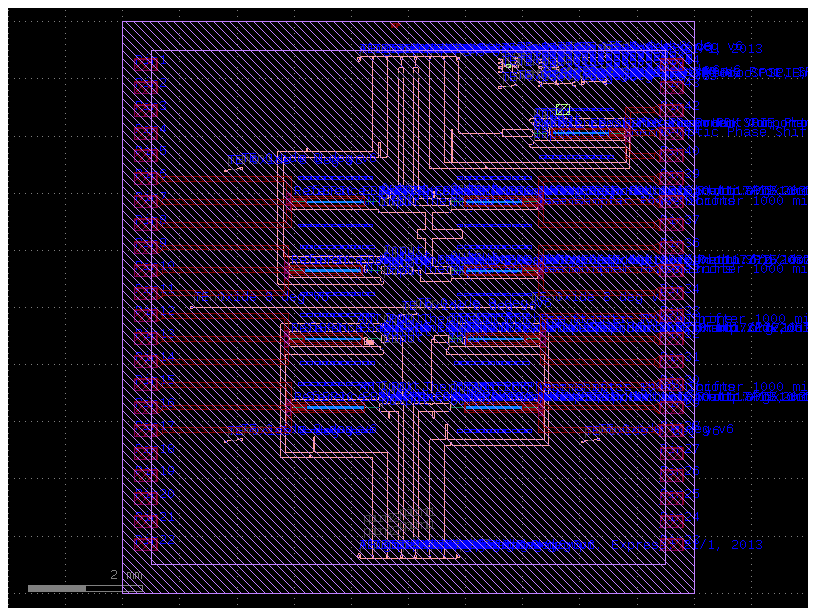

In [145]:
#c.remove_layers(layers=[(1,10)])
c.plot()
c.show()

In [146]:
c.write_gds('CircuitoLucivaldoV3.gds')

WindowsPath('CircuitoLucivaldoV3.gds')